### Imports

In [1]:
import os
import random
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report
from model import CifarTinyNet


### Dataset check + load

In [2]:
DATA_ROOT = "../data"

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

download = not os.path.exists(os.path.join(DATA_ROOT, "cifar-10-batches-py"))

trainset = torchvision.datasets.CIFAR10(
    root=DATA_ROOT, train=True, download=download, transform=transform
)

testset = torchvision.datasets.CIFAR10(
    root=DATA_ROOT, train=False, download=download, transform=transform
)

class_names = trainset.classes


### EDA (class distribution)

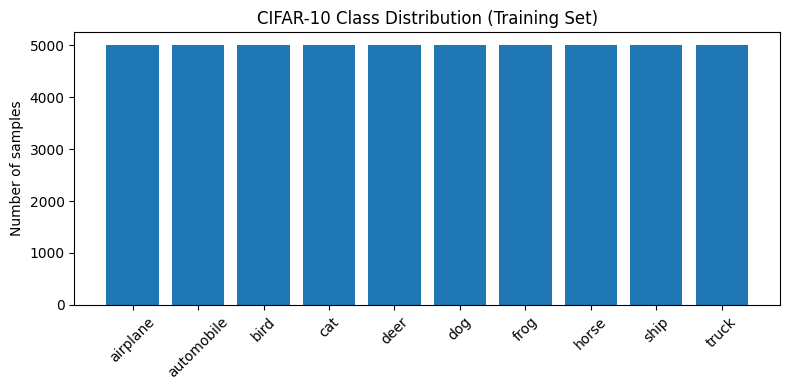

In [3]:
labels = [label for _, label in trainset]
class_counts = np.bincount(labels)

plt.figure(figsize=(8, 4))
plt.bar(class_names, class_counts)
plt.xticks(rotation=45)
plt.ylabel("Number of samples")
plt.title("CIFAR-10 Class Distribution (Training Set)")
plt.tight_layout()
plt.show()


### EDA – Sample Image Grid

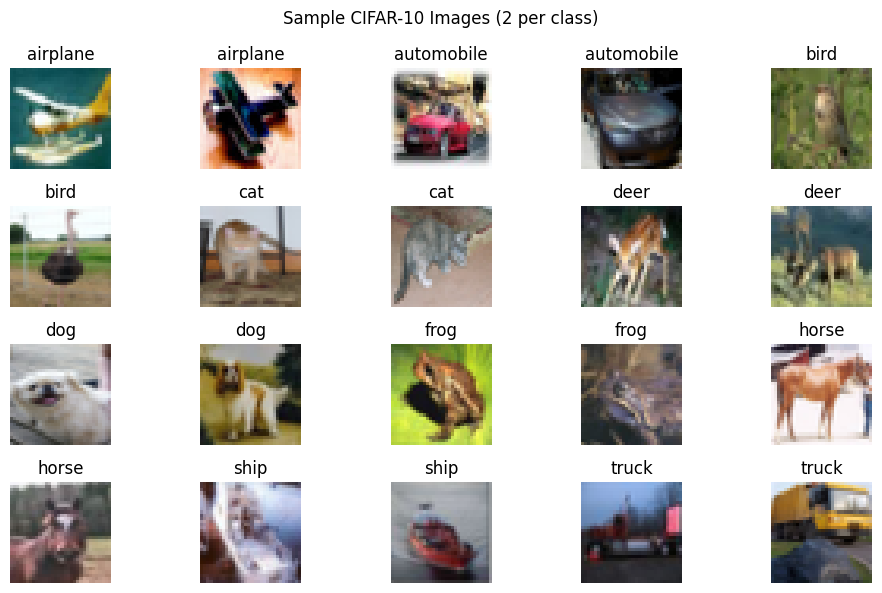

In [4]:
import random

samples_per_class = 2
selected_indices = []

targets = np.array(trainset.targets)

for cls in range(10):
    cls_indices = np.where(targets == cls)[0]
    chosen = np.random.choice(cls_indices, samples_per_class, replace=False)
    selected_indices.extend(chosen)

plt.figure(figsize=(10, 6))

for i, idx in enumerate(selected_indices):
    img, label = trainset[idx]
    img = img * 0.5 + 0.5  # unnormalize

    plt.subplot(4, 5, i + 1)
    plt.imshow(np.transpose(img.numpy(), (1, 2, 0)))
    plt.title(class_names[label])
    plt.axis("off")

plt.suptitle("Sample CIFAR-10 Images (2 per class)")
plt.tight_layout()
plt.show()


### DataLoaders

In [5]:
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=64, shuffle=True
)

testloader = torch.utils.data.DataLoader(
    testset, batch_size=64, shuffle=False
)


### Model, Loss, Optimizer

In [6]:
model = CifarTinyNet()
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


### Train model

In [7]:
num_epochs = 10
losses = []

for epoch in range(num_epochs):
    running_loss = 0.0
    for images, labels in trainloader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    losses.append(running_loss)
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss:.2f}")


Epoch 1/10, Loss: 1218.52
Epoch 2/10, Loss: 971.06
Epoch 3/10, Loss: 876.25
Epoch 4/10, Loss: 807.37
Epoch 5/10, Loss: 756.62
Epoch 6/10, Loss: 719.77
Epoch 7/10, Loss: 683.13
Epoch 8/10, Loss: 654.56
Epoch 9/10, Loss: 627.46
Epoch 10/10, Loss: 603.77


### Training Loss Curve

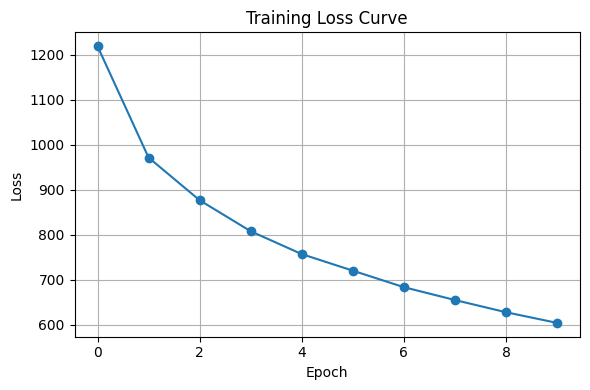

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.grid(True)
plt.tight_layout()
plt.show()


### Evaluate on test set

In [9]:
y_true, y_pred = [], []

model.eval()
with torch.no_grad():
    for images, labels in testloader:
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        y_true.extend(labels.numpy())
        y_pred.extend(preds.numpy())


### Classification report 

In [10]:
report_text = classification_report(
    y_true, y_pred, target_names=class_names
)

print("Classification Report:\n")
print(report_text)

report_dict = classification_report(
    y_true, y_pred, target_names=class_names, output_dict=True
)

df_report = pd.DataFrame(report_dict).transpose()
os.makedirs("../results", exist_ok=True)
df_report.to_csv("../results/classification_report.csv")

print("Saved classification_report.csv")


Classification Report:

              precision    recall  f1-score   support

    airplane       0.72      0.72      0.72      1000
  automobile       0.76      0.82      0.79      1000
        bird       0.55      0.58      0.57      1000
         cat       0.51      0.53      0.52      1000
        deer       0.65      0.56      0.60      1000
         dog       0.62      0.55      0.59      1000
        frog       0.78      0.74      0.76      1000
       horse       0.75      0.69      0.72      1000
        ship       0.71      0.85      0.77      1000
       truck       0.73      0.75      0.74      1000

    accuracy                           0.68     10000
   macro avg       0.68      0.68      0.68     10000
weighted avg       0.68      0.68      0.68     10000

Saved classification_report.csv


### Confusion Matrix

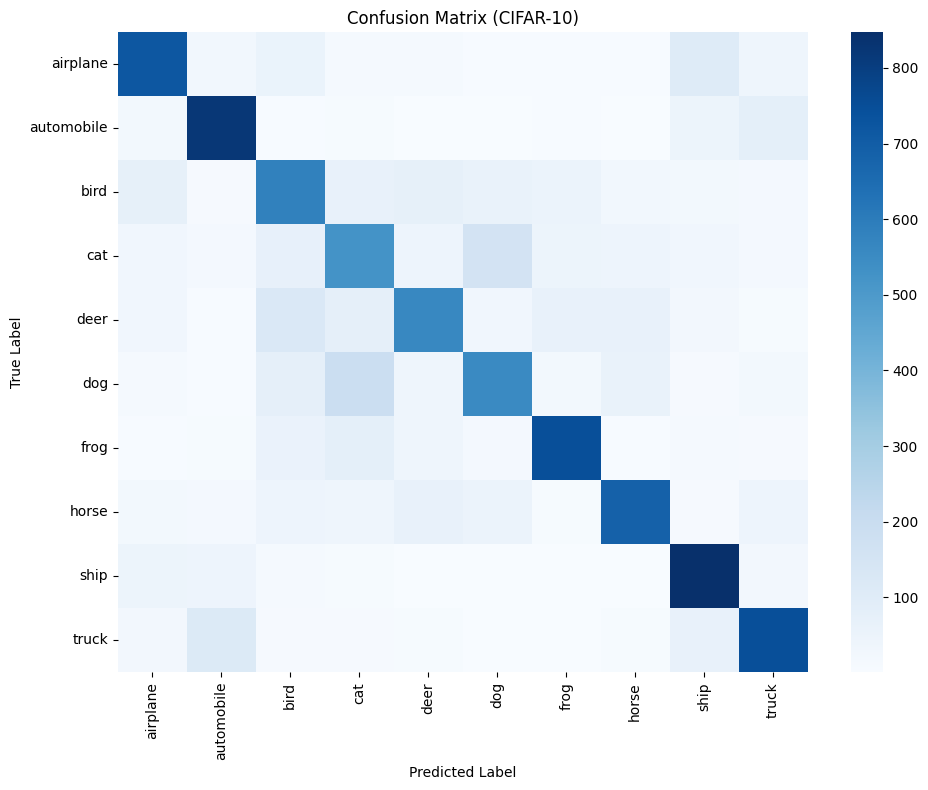

In [11]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (CIFAR-10)")
plt.tight_layout()
plt.savefig("../results/confusion_matrix.png")
plt.show()


### Save Trained Model

In [12]:
torch.save(model.state_dict(), "../models/cifar_tinynet.pth")
print("Saved cifar_tinynet.pth")


Saved cifar_tinynet.pth


### Export ONNX Model

In [13]:
dummy_input = torch.randn(1, 3, 32, 32)

torch.onnx.export(
    model,
    dummy_input,
    "../models/cifar_tinynet.onnx",
    input_names=["input"],
    output_names=["output"]
)

print("Exported cifar_tinynet.onnx")


[torch.onnx] Obtain model graph for `CifarTinyNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `CifarTinyNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...
[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
Exported cifar_tinynet.onnx


### ONNX IR Downgrade (REQUIRED)
- Modern PyTorch exports newer IR
- ONNX Runtime binary supports older IR
- Opset downgrade is unreliable
- IR downgrade is safe and supported

In [14]:
import onnx

onnx_path = "../models/cifar_tinynet.onnx"
onnx_model = onnx.load(onnx_path)

print("Before downgrade:")
print("IR version:", onnx_model.ir_version)

onnx_model.ir_version = 9

onnx.save(onnx_model, onnx_path)

print("After downgrade:")
print("IR version:", onnx_model.ir_version)


Before downgrade:
IR version: 10
After downgrade:
IR version: 9
